##Análisis de cobertura minera en Huepetuhe (capitulo 2)

PARTE 1. Clasificación a partir de MapBiomas Perú
Se debe descargar el archivo.GEOTIFF resultante del Notebook anterior o bien descargarlo del siguiente drive: https://drive.google.com/file/d/1xmdvaP9_CF85bTFbajB8ymgChcTqtajX/view?usp=drive_link

In [ ]:
!pip install rioxarray rasterio planetary-computer pystac-client cartopy geopandas matplotlib -q

In [ ]:
import numpy as np
import xarray as xr
import rioxarray
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import cartopy

In [ ]:
features_recortado = rioxarray.open_rasterio("Huepetuhe_2025_Stack_12Bandas.tif") #abrir el .geotiff anterior

In [ ]:
nombres_bandas = [
    "B02", "B03", "B04", "B08", "B11", "B12",
    "NDVI", "NDWI", "MNDWI", "BSI", "NDMI", "SWIR_RATIO"
]
features_recortado = features_recortado.assign_coords(band=nombres_bandas)

In [ ]:
print("Dimensiones (Bandas, Y, X):", features_recortado.shape)
print("CRS:", features_recortado.rio.crs)
print("Capas disponibles:", features_recortado.band.values)

Dimensiones (Bandas, Y, X): (12, 2160, 3492)
CRS: EPSG:32718
Capas disponibles: ['B02' 'B03' 'B04' 'B08' 'B11' 'B12' 'NDVI' 'NDWI' 'MNDWI' 'BSI' 'NDMI'
 'SWIR_RATIO']


In [ ]:
ndvi  = features_recortado.sel(band="NDVI").values #seleccionamos los indices anteriores
bsi   = features_recortado.sel(band="BSI").values
mndwi = features_recortado.sel(band="MNDWI").values
swir1 = features_recortado.sel(band="B11").values

In [ ]:
mapa_clasificado = np.zeros(ndvi.shape, dtype=np.uint8)
valido = ~np.isnan(ndvi)

In [ ]:
cond_agua    = valido & (mndwi > 0.0) #añadimos las categorías de mapbiomas
cond_mineria = valido & (~cond_agua) & (ndvi < 0.28) & (bsi > 0.02) & (swir1 > 0.14)
cond_sin_veg = valido & (~cond_agua) & (~cond_mineria) & (ndvi < 0.28)
cond_sec     = valido & (ndvi >= 0.28) & (ndvi < 0.65)
cond_bosque  = valido & (ndvi >= 0.65)

mapa_clasificado[cond_agua]    = 33  # Río, lago y pozas mineras
mapa_clasificado[cond_mineria] = 30  # Minería
mapa_clasificado[cond_sin_veg] = 25  # Otras áreas sin vegetación / playas fluviales
mapa_clasificado[cond_sec]     = 15  # Agropecuario / Vegetación secundaria
mapa_clasificado[cond_bosque]  = 3   # Bosque

In [ ]:
da_clasificado = xr.DataArray(
    mapa_clasificado,
    coords={"y": features_recortado.y, "x": features_recortado.x},
    dims=["y", "x"]
)
da_clasificado.rio.write_crs(features_recortado.rio.crs, inplace=True)
da_clasificado.rio.to_raster("Huepetuhe_Clasificacion_MapBiomas.tif", compress="LZW")

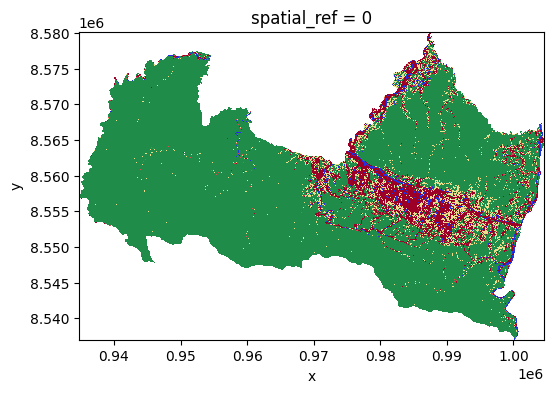

In [ ]:
#establecemos las clases de interés de MapBiomas
clases_info = {
    3:  ("3 - Bosque", "#1f8d49"),
    15: ("15 - Agropecuario / Veg. Secundaria", "#edde8e"),
    25: ("25 - Otras áreas sin vegetación", "#db4d4f"),
    30: ("30 - Minería", "#9c0027"),
    33: ("33 - Río, lago y pozas", "#2532e4"),
}

colores = [clases_info[c][1] for c in clases_info]
cmap_mb = mcolors.ListedColormap(colores)
norm = mcolors.BoundaryNorm([2, 10, 20, 28, 31, 35], cmap_mb.N)
fig, ax = plt.subplots(figsize=(6, 4))
da_clasificado.where(da_clasificado > 0).plot(ax=ax, cmap=cmap_mb, norm=norm, add_colorbar=False)




--- Superficie Estimada por Categoría (ha) ---
3 - Bosque                            : 127,738.20 ha
15 - Agropecuario / Veg. Secundaria   : 8,845.20 ha
25 - Otras áreas sin vegetación       : 803.52 ha
30 - Minería                          : 12,872.00 ha
33 - Río, lago y pozas                : 2,702.48 ha


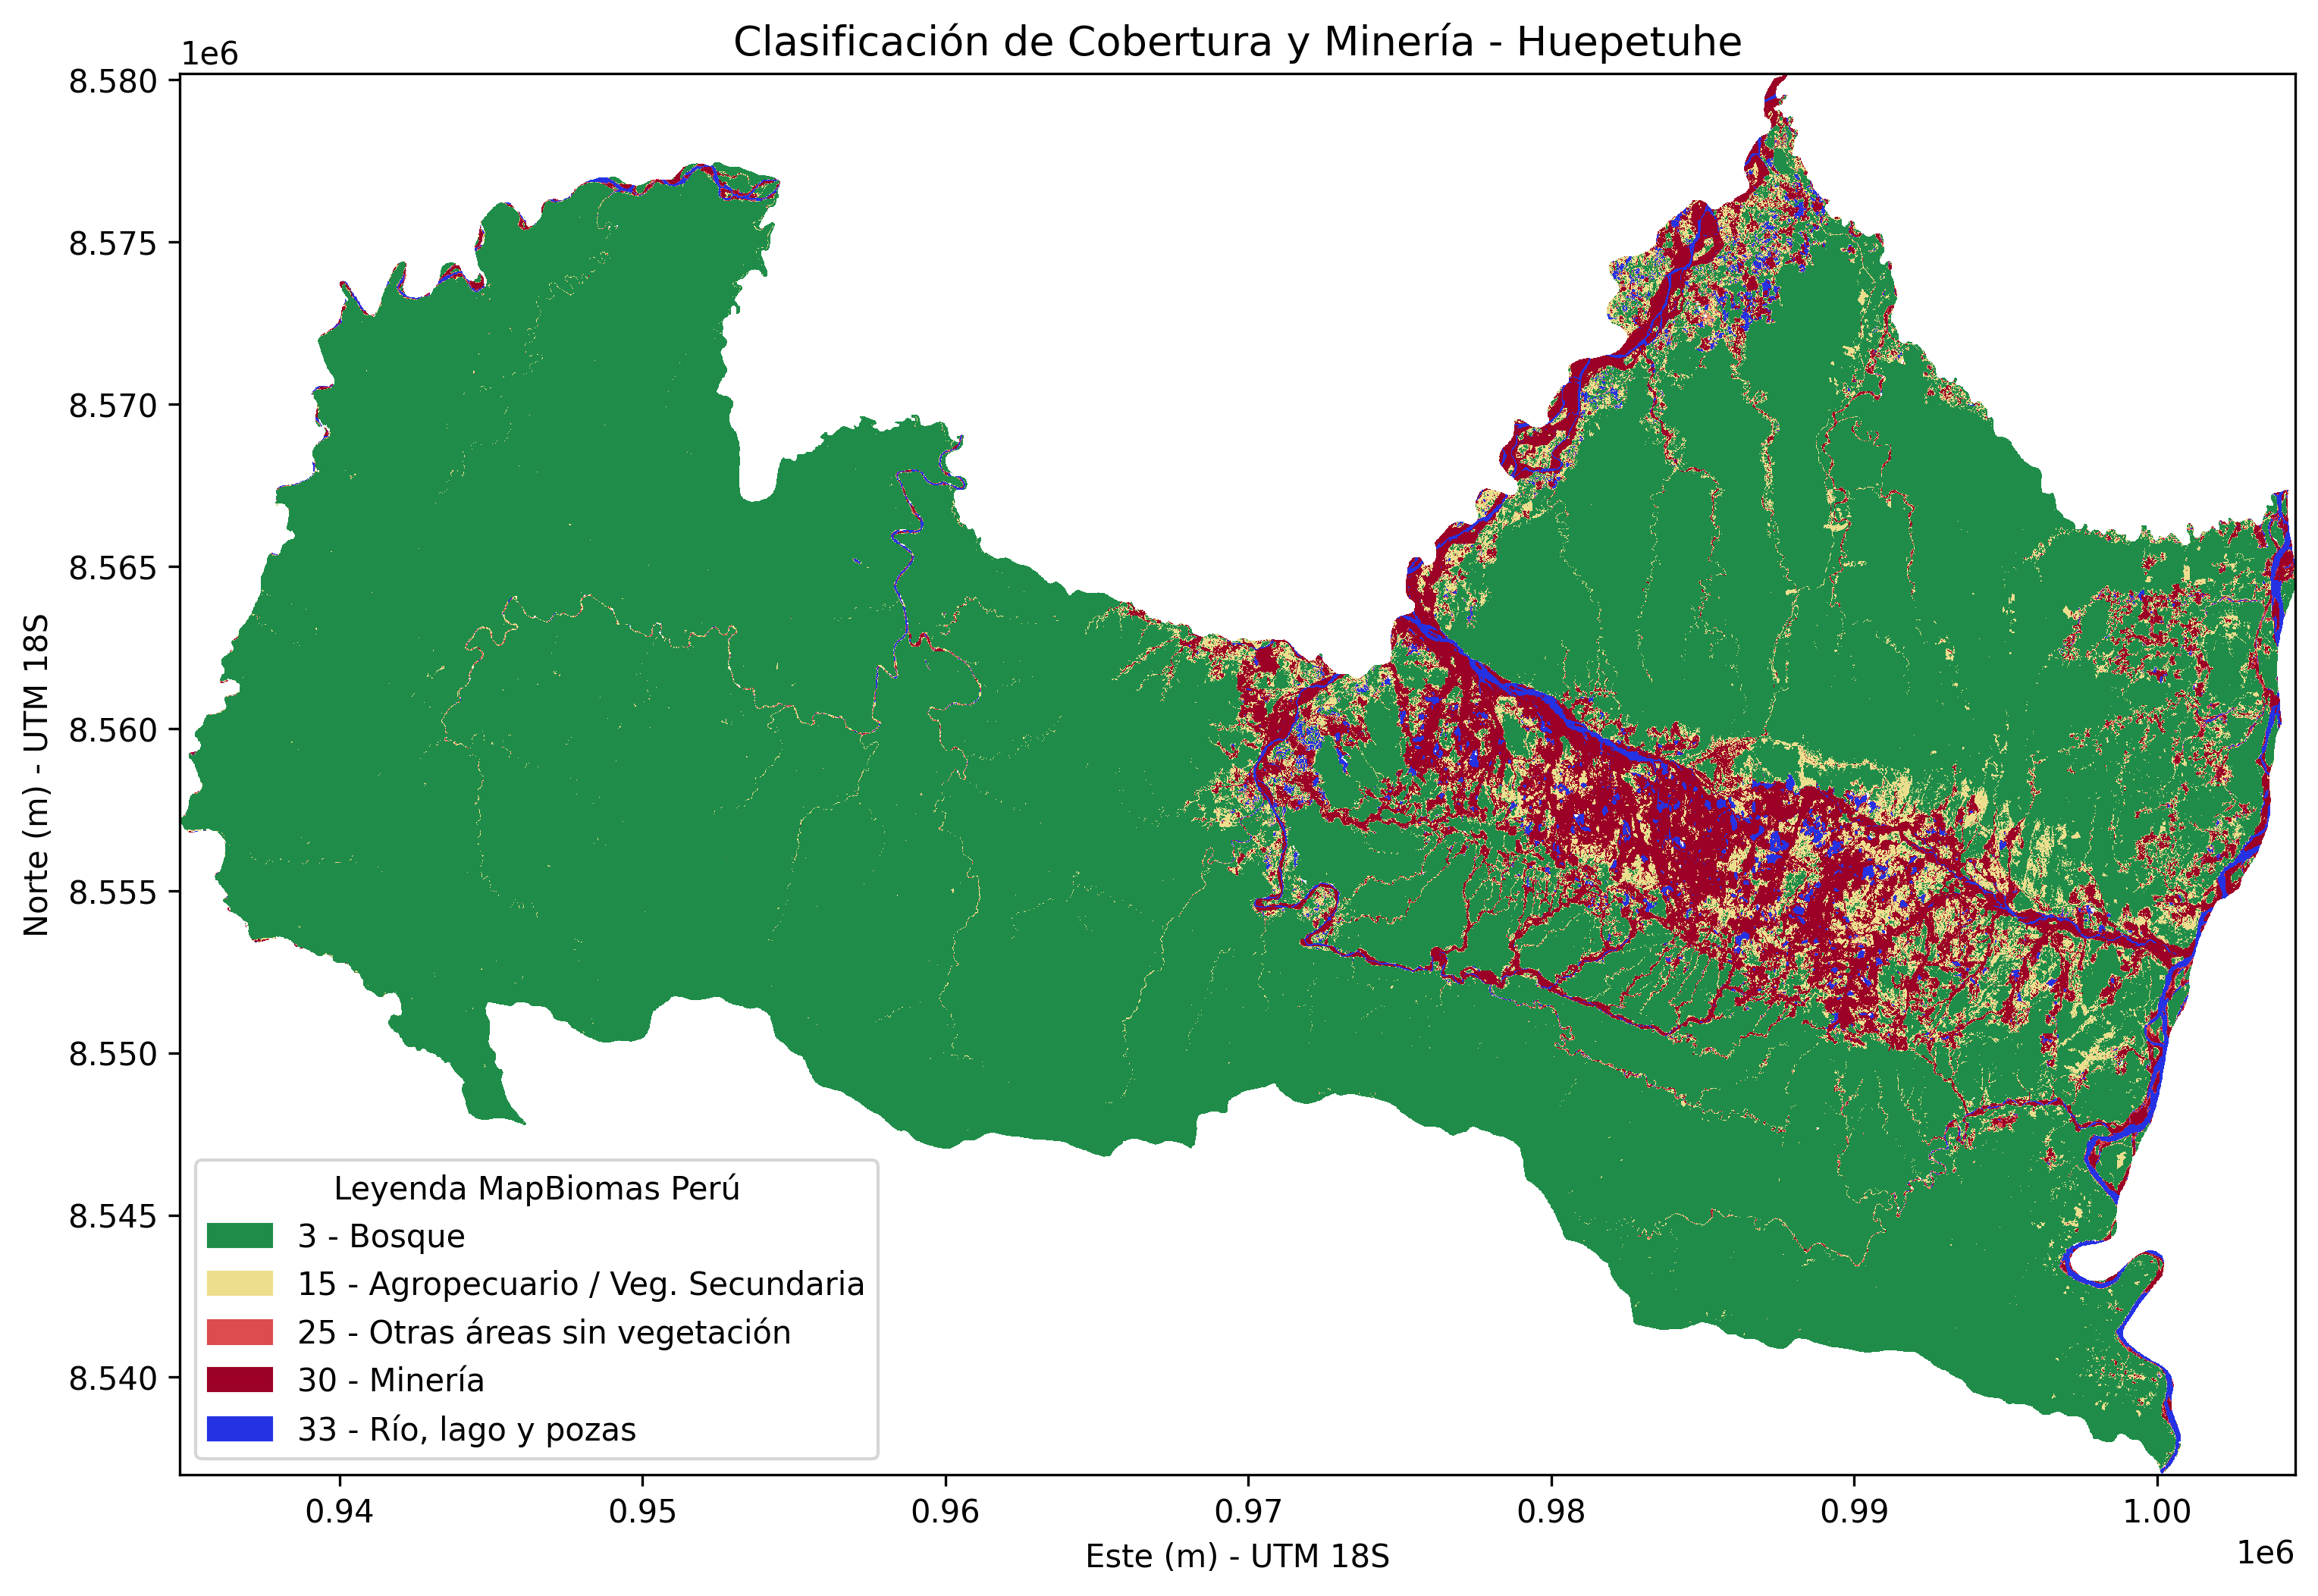

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)
da_clasificado.where(da_clasificado > 0).plot(ax=ax, cmap=cmap_mb, norm=norm, add_colorbar=False)

parches = [mpatches.Patch(color=col, label=lbl) for lbl, col in clases_info.values()]
ax.legend(handles=parches, loc="lower left", title="Leyenda MapBiomas Perú", frameon=True)
ax.set_title("Clasificación de Cobertura y Minería - Huepetuhe", fontsize=13)
ax.set_xlabel("Este (m) - UTM 18S")
ax.set_ylabel("Norte (m) - UTM 18S") #visualizamos

print("\n--- Superficie Estimada por Categoría (ha) ---")
for cod, (nombre, _) in clases_info.items():
    hectareas = np.sum(mapa_clasificado == cod) * 0.04
    print(f"{nombre:<38}: {hectareas:,.2f} ha") #calculo de hectareas

plt.show()

PARTE 2. Entrenamiento del modelo con Random Forest

In [ ]:
from rasterio.enums import Resampling
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [ ]:
stack = rioxarray.open_rasterio("Huepetuhe_2025_Stack_12Bandas.tif")
nombres_bandas = [
    "B02", "B03", "B04", "B08", "B11", "B12",
    "NDVI", "NDWI", "MNDWI", "BSI", "NDMI", "SWIR_RATIO"
]
stack = stack.assign_coords(band=nombres_bandas)

In [ ]:
mapbiomas = rioxarray.open_rasterio("/content/Huepetuhe_Clasificacion_MapBiomas.tif").squeeze()
mapbiomas_alineado = mapbiomas.rio.reproject_match(
    stack,
    resampling=Resampling.nearest  # Conserva los códigos enteros exactos (3, 15, 25, 30, 33)
)

In [ ]:
X_cubo = np.moveaxis(stack.values, 0, -1)
n_filas, n_cols, n_bandas = X_cubo.shape

X_flat = X_cubo.reshape(-1, n_bandas)
y_flat = mapbiomas_alineado.values.reshape(-1)

In [ ]:
clases_interes = [3, 15, 18, 25, 30, 33]
mascara_validos = (~np.isnan(X_flat).any(axis=1)) & np.isin(y_flat, clases_interes)

X_valid = X_flat[mascara_validos]
y_valid = y_flat[mascara_validos].astype(int)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_valid, y_valid, train_size=0.2, stratify=y_valid, random_state=42
)

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=18,
    min_samples_leaf=10,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=42
) #entrenamos el modelo con RandomForest
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced_subsample', max_depth=18,
                       min_samples_leaf=10, n_estimators=200, n_jobs=-1,
                       random_state=42)

In [ ]:
y_pred = rf.predict(X_test)
print(f"Exactitud Global (Overall Accuracy): {accuracy_score(y_test, y_pred):.2%}\n")
print("--- Reporte de Clasificación (Random Forest) ---")
print(classification_report(y_test, y_pred)) #vemos la clasificación de pixeles

Exactitud Global (Overall Accuracy): 100.00%

--- Reporte de Clasificación (Random Forest) ---
              precision    recall  f1-score   support

           3       1.00      1.00      1.00   2554764
          15       1.00      1.00      1.00    176904
          25       1.00      1.00      1.00     16070
          30       1.00      1.00      1.00    257440
          33       1.00      1.00      1.00     54050

    accuracy                           1.00   3059228
   macro avg       1.00      1.00      1.00   3059228
weighted avg       1.00      1.00      1.00   3059228



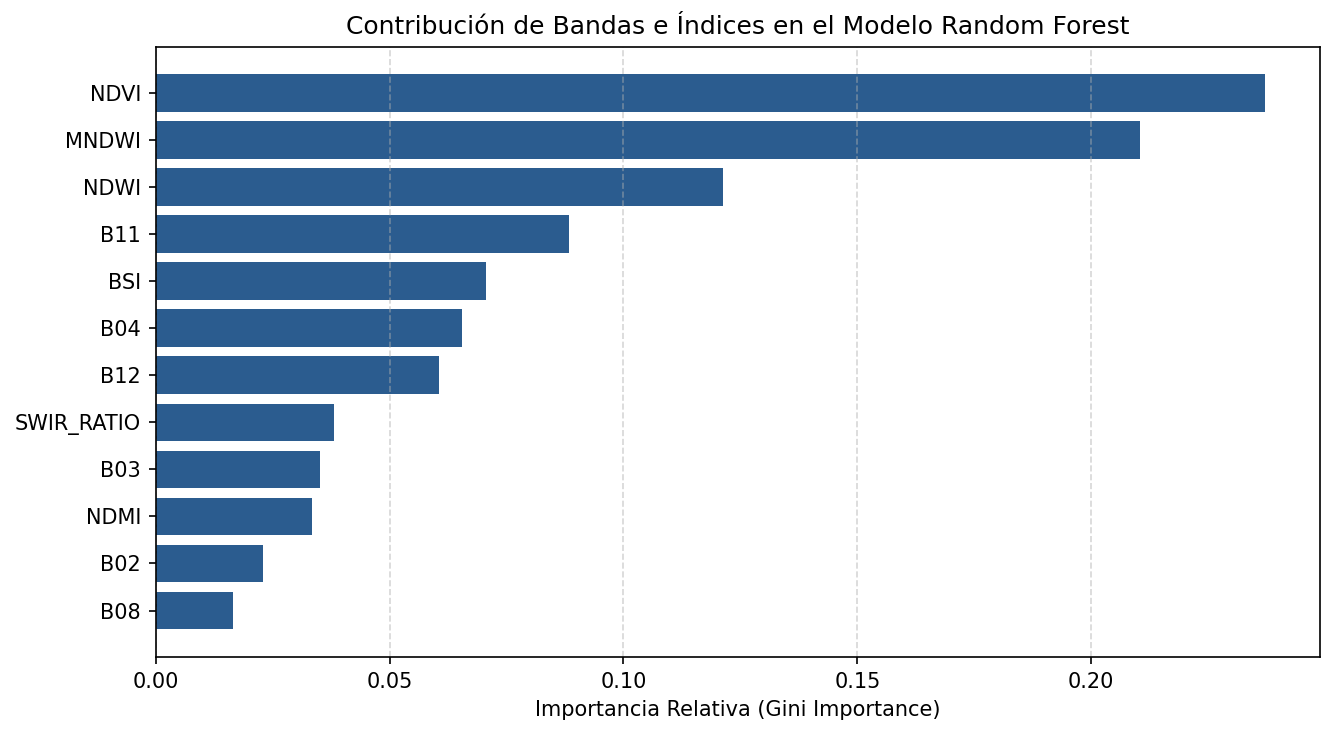

In [ ]:
importancias = rf.feature_importances_
indices_ord = np.argsort(importancias)

fig, ax = plt.subplots(figsize=(9, 5), dpi=150)
ax.barh([nombres_bandas[i] for i in indices_ord], importancias[indices_ord], color="#2b5c8f")
ax.set_xlabel("Importancia Relativa")
ax.set_title("Contribución de Bandas e Índices en el Modelo Random Forest")
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show() #graficamos según la contribución de las bandas

In [ ]:
predicciones = np.zeros(X_flat.shape[0], dtype=np.uint8)
mascara_no_nan = ~np.isnan(X_flat).any(axis=1)
predicciones[mascara_no_nan] = rf.predict(X_flat[mascara_no_nan])

mapa_rf = predicciones.reshape(n_filas, n_cols) #resultado tras random forest

In [ ]:
da_rf = xr.DataArray(
    mapa_rf,
    coords={"y": stack.y, "x": stack.x},
    dims=["y", "x"]
)
da_rf.rio.write_crs(stack.rio.crs, inplace=True)
da_rf.rio.to_raster("Huepetuhe_RandomForest_MapBiomas.tif", compress="LZW")

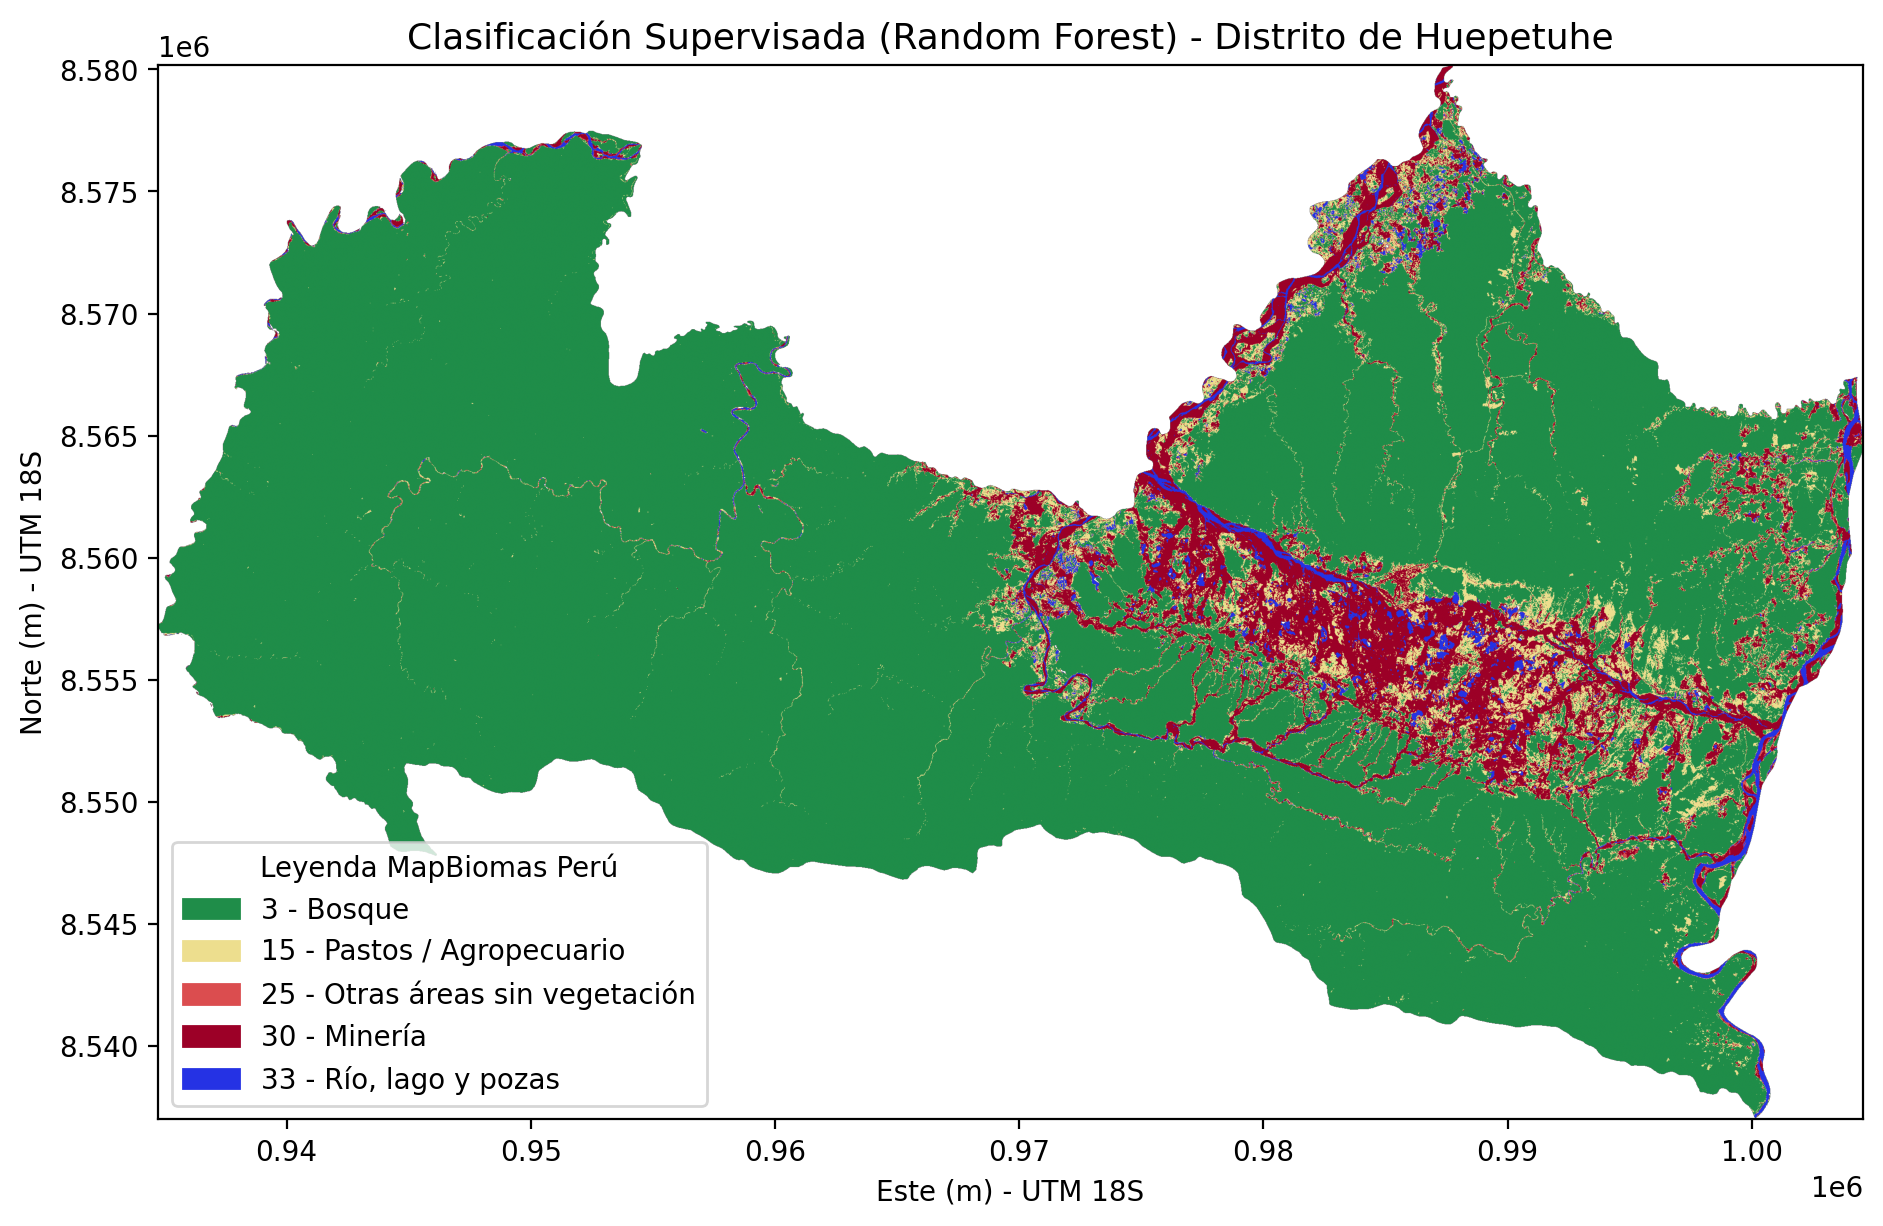

In [ ]:
clases_info = {
    3:  ("3 - Bosque", "#1f8d49"),
    15: ("15 - Pastos / Agropecuario", "#edde8e"),
    18: ("18 - Agricultura", "#e974ed"),
    25: ("25 - Otras áreas sin vegetación", "#db4d4f"),
    30: ("30 - Minería", "#9c0027"),
    33: ("33 - Río, lago y pozas", "#2532e4"),
}

clases_presentes = [c for c in clases_info if np.any(mapa_rf == c)]
colores = [clases_info[c][1] for c in clases_presentes]
cmap_mb = mcolors.ListedColormap(colores)

mapa_indexado = np.full(mapa_rf.shape, np.nan)
for idx, cod in enumerate(clases_presentes):
    mapa_indexado[mapa_rf == cod] = idx

fig, ax = plt.subplots(figsize=(11, 11), dpi=200)
ax.imshow(
    mapa_indexado,
    cmap=cmap_mb,
    extent=[stack.x.min(), stack.x.max(), stack.y.min(), stack.y.max()]
)

parches = [mpatches.Patch(color=clases_info[c][1], label=clases_info[c][0]) for c in clases_presentes]
ax.legend(handles=parches, loc="lower left", title="Leyenda MapBiomas Perú", frameon=True)
ax.set_title("Clasificación Supervisada (Random Forest) - Distrito de Huepetuhe", fontsize=13)
ax.set_xlabel("Este (m) - UTM 18S")
ax.set_ylabel("Norte (m) - UTM 18S")
plt.savefig("Mapa_RandomForest_Huepetuhe.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show() #graficamos

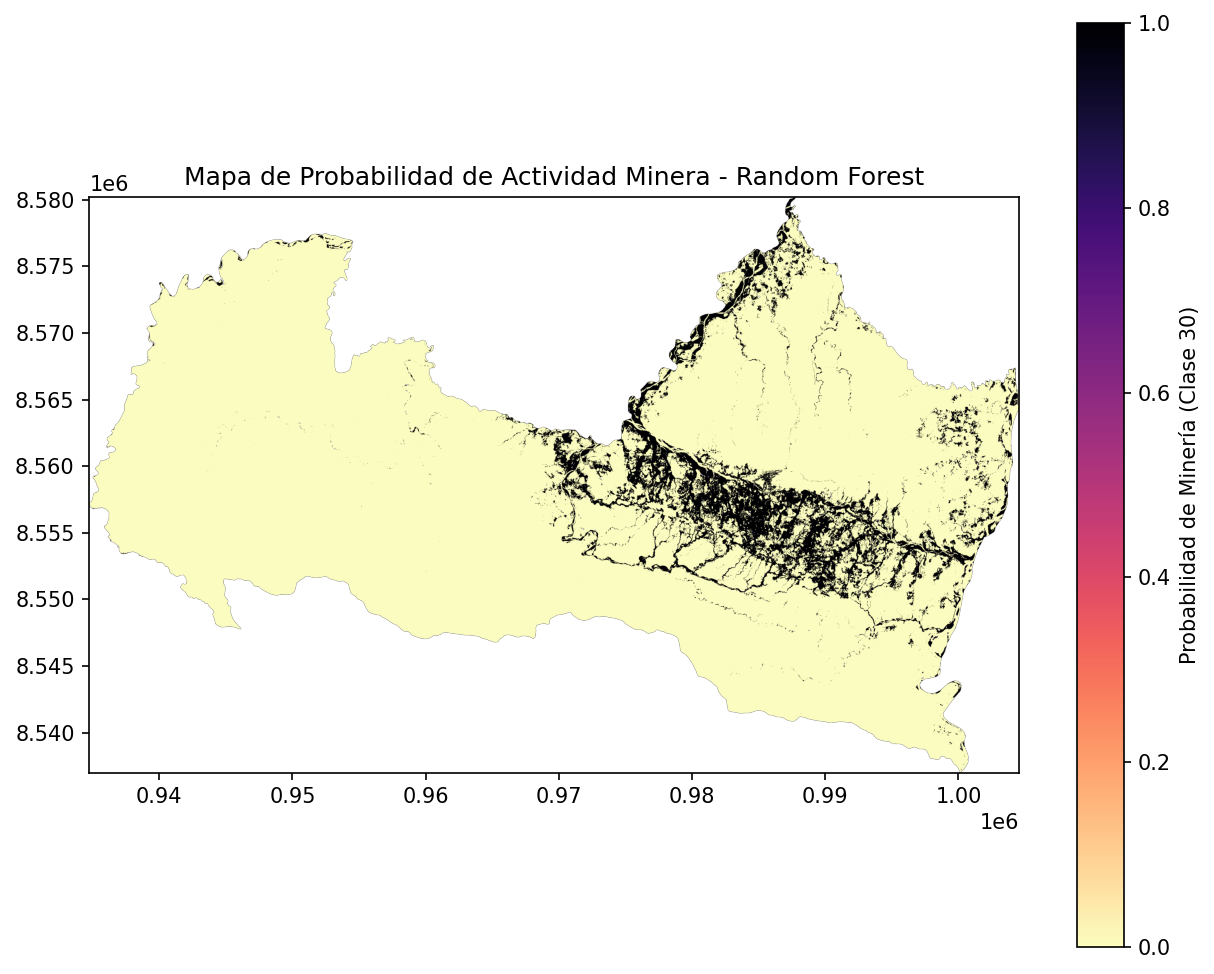

In [ ]:
idx_mineria = list(rf.classes_).index(30)
prob_flat = np.full(X_flat.shape[0], np.nan, dtype=np.float32)
prob_flat[mascara_no_nan] = rf.predict_proba(X_flat[mascara_no_nan])[:, idx_mineria]

mapa_prob_mineria = prob_flat.reshape(n_filas, n_cols) #mapa de probabilidad de actividad minera a partir de los resultados del entrenamiento del modelo

plt.figure(figsize=(10, 8), dpi=300)
plt.imshow(mapa_prob_mineria, cmap="magma_r", vmin=0, vmax=1,
           extent=[stack.x.min(), stack.x.max(), stack.y.min(), stack.y.max()])
plt.colorbar(label="Probabilidad de Minería (Clase 30)")
plt.title("Mapa de Probabilidad de Actividad Minera 2025 - Random Forest")
plt.savefig("Mapa de Probabilidad de Actividad Minera 2025-Random Forest.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [ ]:
res_x = abs(float(stack.x[1] - stack.x[0]))
res_y = abs(float(stack.y[1] - stack.y[0]))
area_pixel_ha = (res_x * res_y) / 10000.0

In [ ]:
rangos = [
    ("Baja (20% - 50%)", (mapa_prob_mineria >= 0.20) & (mapa_prob_mineria < 0.50)),
    (
        "Moderada (50% - 75%)",
        (mapa_prob_mineria >= 0.50) & (mapa_prob_mineria < 0.75),
    ),
    ("Alta (75% - 90%)", (mapa_prob_mineria >= 0.75) & (mapa_prob_mineria < 0.90)),
    ("Muy Alta (90% - 100%)", (mapa_prob_mineria >= 0.90)),
]

etiquetas = [r[0] for r in rangos]
hectareas = [np.sum(r[1]) * area_pixel_ha for r in rangos]
# Colores inspirados en tu paleta magma_r
colores = ["#feb078", "#b73779", "#51127c", "#000004"]

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=300)
barras = ax.bar(
    etiquetas, hectareas, color=colores, edgecolor="black", width=0.55
)

for barra in barras:
  alto = barra.get_height()
  ax.text(
      barra.get_x() + barra.get_width() / 2,
      alto + (max(hectareas) * 0.02),
      f"{alto:,.2f} ha",
      ha="center",
      fontsize=10,
      fontweight="bold",
  )

# Calcular el total con probabilidad >= 50% (umbral estándar de clasificación)
total_probable = sum(hectareas[1:])

ax.set_ylim(0, max(hectareas) * 1.18)
ax.set_ylabel("Superficie (Hectáreas)", fontsize=11)
ax.set_title(
    "Superficie por Probabilidad de Actividad Minera (2025)\nÁrea con"
    f" probabilidad ≥ 50%: {total_probable:,.2f} ha",
    fontsize=12,
    fontweight="bold",
)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.savefig(
    "Hectareas_Probabilidad_Mineria_2025.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()